# 20 · Expectedness scores (work package 9)

**Work package 9** of the [applications plan](../../research/implementation_plan_applications.md), section 9.
For every positive pair (account, token picked up in the two days after a point) at every evaluation point: how
far down the account's ranking under the frozen fixed blend the token was. WP13 and WP14 build on these scores,
and WP11 uses them as a feature.

- **Rank:** the number of tokens the account had not traded with a strictly higher score; 0 is the model's first
  choice. A pair is a hit of the top-10 list when its rank is below 10.
- **Rank percentile:** rank / (candidates − 1): 0 is the first choice, 1 the last.
- **Cold pairs:** tokens born after the point have no rank and are kept as their own group.

The tables were built by `src/scripts/build_expectedness.py` (results/wp9/, local). This notebook checks them
against the protocol and describes them by part, token age, popularity and history size.

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import expectedness as ex
import plots
import protocol as pc
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
WP9 = pc.RESULTS_DIR / "wp9"
PARTS = ["dev_a", "dev_b", "test"]
pairs = pd.concat([pd.read_parquet(WP9 / f"pairs_{part}.parquet").assign(part=part) for part in PARTS], ignore_index=True)
pairs["hit"] = pairs["rank"] < 10
print(f"{len(pairs):,} positive pairs at {pairs['point'].nunique()} points")
pairs.groupby("part").agg(points=("point", "nunique"), pairs=("user", "size"), accounts=("user", "nunique"), cold_share=("cold", "mean"))

677,792 positive pairs at 35 points


,points,pairs,accounts,cold_share
part,,,,
dev_a,10,178987,39104,0.249
dev_b,11,198947,30254,0.315
test,14,299858,44839,0.292


## 1. Check against the protocol

At one point of each part, recall per account computed from the ranks (hits = pairs with rank below 10, divided by
all positive pairs including cold ones) must equal the recall of `protocol.evaluate_point` for the same model.
Ties at the 10th place could make them differ slightly; with continuous blend scores they should not.

In [2]:
legs = td.load_legs()
rows = []
for part in PARTS:
    t = pc.POINTS[part][0]
    task = pc.load_task(legs, t)
    scorer, _, _ = ex.blend_model(task)
    per_user, _ = pc.evaluate_point(scorer, task)
    at_point = pairs[pairs["point"] == t]
    from_ranks = at_point.groupby("user").agg(hits=("hit", "sum"), positives=("hit", "size"))
    from_ranks["recall"] = from_ranks["hits"] / from_ranks["positives"]
    joined = per_user.set_index("user")[["recall"]].join(from_ranks["recall"].rename("recall_from_ranks"))
    rows.append({"part": part, "point": t, "accounts": len(joined), "recall_protocol": joined["recall"].mean(),
                 "recall_from_ranks": joined["recall_from_ranks"].mean(),
                 "accounts_that_differ": int((~np.isclose(joined["recall"], joined["recall_from_ranks"])).sum())})  # fmt: skip
check = pd.DataFrame(rows)
check

,part,point,accounts,recall_protocol,recall_from_ranks,accounts_that_differ
0,dev_a,2026-07-02 00:00:00+00:00,9606,0.201,0.201,1
1,dev_b,2026-07-22 00:00:00+00:00,5117,0.151,0.151,0
2,test,2026-08-13 00:00:00+00:00,5456,0.144,0.144,1


## 2. How expected are the tokens accounts pick up?

The distribution of rank percentiles of warm pairs, by part. A model that ranked at random would give a uniform
distribution (median 0.5). Shares: in the top-10 list (a hit), in the best 1%, and in the worst half.

In [3]:
warm = pairs[~pairs["cold"]]
summary = warm.groupby("part").agg(
    pairs=("rank", "size"),
    median_percentile=("rank_percentile", "median"),
    hit_share=("hit", "mean"),
    best_1pct=("rank_percentile", lambda p: (p <= 0.01).mean()),
    worst_half=("rank_percentile", lambda p: (p > 0.5).mean()),
    no_path=("max_similarity", lambda s: (s == 0).mean()),
)
summary.loc[PARTS]

,pairs,median_percentile,hit_share,best_1pct,worst_half,no_path
part,,,,,,
dev_a,134473,0.007,0.173,0.566,0.008,0.198
dev_b,136214,0.008,0.118,0.536,0.014,0.284
test,212448,0.004,0.128,0.648,0.003,0.250


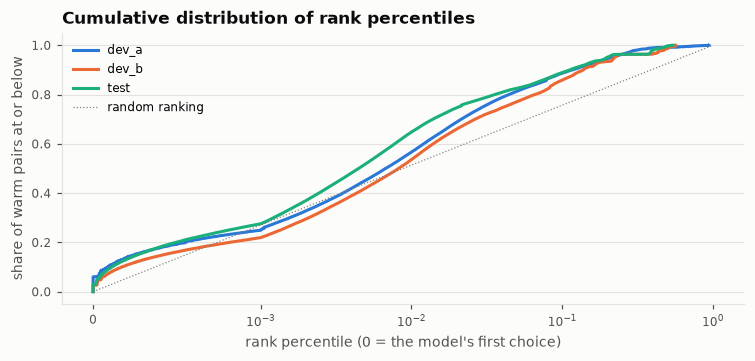

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for slot, part in enumerate(PARTS):
    values = np.sort(warm.loc[warm["part"] == part, "rank_percentile"].to_numpy())
    ax.plot(values, np.arange(1, len(values) + 1) / len(values), color=plots.SERIES[slot], label=part)
ax.plot([0, 1], [0, 1], color="grey", linewidth=0.8, linestyle=":", label="random ranking")
ax.set_xscale("symlog", linthresh=1e-3)
ax.set_xlabel("rank percentile (0 = the model's first choice)")
ax.set_ylabel("share of warm pairs at or below")
ax.set_title("Cumulative distribution of rank percentiles")
ax.legend()
plt.show()

## 3. By token age and popularity

Token age at the point (days since its first trade in the data), and whether the token is in the popular head.
New tokens have few co-traders, so the neighbour part of the blend knows little about them.

In [5]:
warm = warm.assign(age_group=pd.cut(warm["token_age_days"], [0, 1, 3, 7, 14, np.inf], labels=["<1 d", "1-3 d", "3-7 d", "7-14 d", ">14 d"]))
by_age = warm.groupby(["age_group", "part"], observed=True).agg(
    pairs=("rank", "size"), median_percentile=("rank_percentile", "median"), hit_share=("hit", "mean"), no_path=("max_similarity", lambda s: (s == 0).mean())
)
by_age.unstack("part")

pairs                 median_percentile             hit_share  \
part       dev_a   dev_b    test             dev_a dev_b  test     dev_a   
age_group                                                                  
<1 d        6905    3129    4669             0.000 0.012 0.005     0.509   
1-3 d       2573    2224    3327             0.012 0.009 0.021     0.211   
3-7 d       5464    1579    2256             0.002 0.009 0.011     0.399   
7-14 d     19688    1845    2467             0.011 0.034 0.005     0.147   
>14 d      99843  127437  199729             0.007 0.008 0.004     0.142   

                      no_path              
part      dev_b  test   dev_a dev_b  test  
age_group                                  
<1 d      0.106 0.110   0.238 0.302 0.249  
1-3 d     0.085 0.119   0.312 0.305 0.507  
3-7 d     0.116 0.079   0.233 0.326 0.432  
7-14 d    0.062 0.265   0.229 0.447 0.299  
>14 d     0.119 0.127   0.184 0.280 0.243

In [6]:
warm.groupby(["in_head", "part"]).agg(pairs=("rank", "size"), median_percentile=("rank_percentile", "median"), hit_share=("hit", "mean")).unstack("part")

pairs                 median_percentile             hit_share        \
part      dev_a   dev_b    test             dev_a dev_b  test     dev_a dev_b   
in_head                                                                         
False    107859  106695  161102             0.012 0.015 0.008     0.057 0.026   
True      26614   29519   51346             0.000 0.000 0.000     0.644 0.449   

               
part     test  
in_head        
False   0.031  
True    0.432

## 4. By history size

The history groups of the project (tokens in the account's 14-day window): 1, 2-4, 5 or more.

In [7]:
warm = warm.assign(group=pc.history_group(warm["window_size"].to_numpy()))
warm.groupby(["group", "part"]).agg(pairs=("rank", "size"), median_percentile=("rank_percentile", "median"), hit_share=("hit", "mean")).unstack("part")

pairs                median_percentile             hit_share        \
part   dev_a  dev_b    test             dev_a dev_b  test     dev_a dev_b   
group                                                                       
1      23085  21135   33570             0.002 0.004 0.003     0.339 0.222   
2-4    24471  23971   40242             0.004 0.006 0.003     0.253 0.175   
5+     86917  91108  138636             0.009 0.010 0.005     0.107 0.079   

             
part   test  
group        
1     0.221  
2-4   0.203  
5+    0.083

## 5. Hits against misses

For the pairs the top-10 list missed: how far down were they? A miss at percentile 0.02 is a near miss; one above
0.9 is a token the model considered among the least likely for that account. Also: of the misses, the share with
no co-trading path to the account's tokens (`max_similarity` = 0), which only popularity could have found.

In [8]:
misses = warm[~warm["hit"]]
bins = [0, 0.001, 0.01, 0.1, 0.5, 0.9, 1.0]
labels = ["<=0.1%", "0.1-1%", "1-10%", "10-50%", "50-90%", ">90%"]
table = misses.assign(band=pd.cut(misses["rank_percentile"], bins, labels=labels, include_lowest=True))
shares = table.groupby(["part", "band"], observed=False).size().unstack("part")
(shares / shares.sum()).loc[labels, PARTS]

part,dev_a,dev_b,test
band,,,
<=0.1%,0.092,0.115,0.169
0.1-1%,0.384,0.359,0.427
1-10%,0.387,0.366,0.277
10-50%,0.127,0.145,0.123
50-90%,0.009,0.015,0.004
>90%,0.001,0.000,0.000


In [9]:
misses.groupby("part").agg(misses=("rank", "size"), no_path_share=("max_similarity", lambda s: (s == 0).mean()),
                           median_rank=("rank", "median")).loc[PARTS]  # fmt: skip

,misses,no_path_share,median_rank
part,,,
dev_a,111201,0.238,291.000
dev_b,120171,0.321,429.000
test,185335,0.285,321.000


## 6. Summary for the packages that use these scores

The shares that WP13 (scam push) and WP14 (alerts) build on: pairs with a percentile above 0.9 (the model's least
expected picks) and pairs without a co-trading path, per point, with their spread across points.

In [10]:
per_point = warm.groupby(["part", "point"]).agg(
    low_rank_share=("rank_percentile", lambda p: (p > 0.9).mean()), no_path_share=("max_similarity", lambda s: (s == 0).mean())
)
per_point.groupby("part").agg(["mean", "min", "max"]).loc[PARTS]

low_rank_share             no_path_share            
                mean   min   max          mean   min   max
part                                                      
dev_a          0.001 0.000 0.009         0.201 0.143 0.254
dev_b          0.000 0.000 0.000         0.277 0.232 0.369
test           0.000 0.000 0.000         0.249 0.187 0.293

## 7. What this shows

- **The ranks agree with the protocol.** Recall from the ranks equals the recall of `protocol.evaluate_point` at
  the three points checked (one account differs at two of them, from ties at the 10th place).
- **Picked-up tokens are almost always near the top.** The median rank percentile is below 0.01 in every part, and
  more than half of the warm pairs fall in the best 1%. Almost no pair is above 0.9. The universe holds every token
  ever traded, most of them inactive, and these score at or near zero; a token someone picks up is nearly always an
  active one, so it ranks above all inactive tokens. The percentile is therefore compressed toward 0, and the
  **raw rank** (median rank of a miss: about 300-430) separates pairs much better.
- **Consequence for WP13:** its feature "low-rank share" (percentile above 0.9) is zero almost everywhere and would
  carry no information. It should be defined on the rank instead (for example rank above 1,000, or the percentile
  among tokens active in the 14-day window). This is a change to the applications plan and is decided before WP13
  starts.
- **No co-trading path:** a quarter of the warm pairs (20-28% by part) have no similarity path from the account's
  tokens; only the popularity part of the blend can rank them. This share is WP13's "unexplained share".
- **Popular head and history size:** head tokens are found (hit share 43-64%), tail tokens rarely (3-6%); accounts
  with one token in their window are served best (hit share 22-34%), accounts with five or more worst (8-11%).